# GA1 Final Model 2 — k-NN booster classification

Target: `vac_boost_1` (whether the respondent received a COVID-19 booster or third dose). This single notebook reproduces data cleaning, EDA, training-only feature selection, missing-value handling, k-NN cross-validation, candidate comparison, and the locked final test evaluation. Run top-to-bottom with the original CSV in the same folder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

input_path = Path("COVID-19BehaviorData_CAN2022.csv")
if not input_path.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"Put {input_path.name} in the same folder as this notebook, then run again."
        ) from exc
    print(f"Upload {input_path.name} to the Colab runtime.")
    uploaded = files.upload()
    if input_path.name not in uploaded:
        raise FileNotFoundError(f"Upload the file named {input_path.name} to continue.")

data = pd.read_csv(input_path, low_memory=False)
print(f"Original shape: {data.shape[0]:,} rows × {data.shape[1]:,} columns")
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

Original shape: 6,430 rows × 512 columns


## 1. Reproduce cleaning and target definition

Convert whitespace and `__NA__` to missing values, remove columns that are empty for all respondents, and define `vac_boost_1`. The 644 skipped booster responses all belong to respondents with neither first nor second dose, so they are inferred as `No`, matching Model 1.

In [2]:
text_columns = data.select_dtypes(include=["object", "string"]).columns
data[text_columns] = data[text_columns].replace(r"^\s*$", pd.NA, regex=True)
data[text_columns] = data[text_columns].replace("__NA__", pd.NA)
cleaned_data = data.dropna(axis=1, how="all").copy()

original_booster_response = cleaned_data["vac_boost_1"].copy()
skipped_target = original_booster_response.isna()
assert skipped_target.sum() == 644
assert (cleaned_data.loc[skipped_target, "vac"] == "No, neither").all()
cleaned_data["vac_boost_1"] = original_booster_response.fillna("No")
cleaned_data = cleaned_data.where(cleaned_data.notna(), np.nan)
print(f"Nonempty-column shape: {cleaned_data.shape[0]:,} × {cleaned_data.shape[1]:,}")
print(cleaned_data["vac_boost_1"].value_counts().to_string())

Nonempty-column shape: 6,430 × 159
vac_boost_1
Yes    3646
No     2784


## 2. Exploratory data analysis

Describe the binary target and its relationship with three important complete predictors. These plots use the full survey only for descriptive reporting; all variable selection and hyperparameter tuning below remain training-only.

Target distribution:
            n  percent
booster               
Yes      3646     56.7
No       2784     43.3


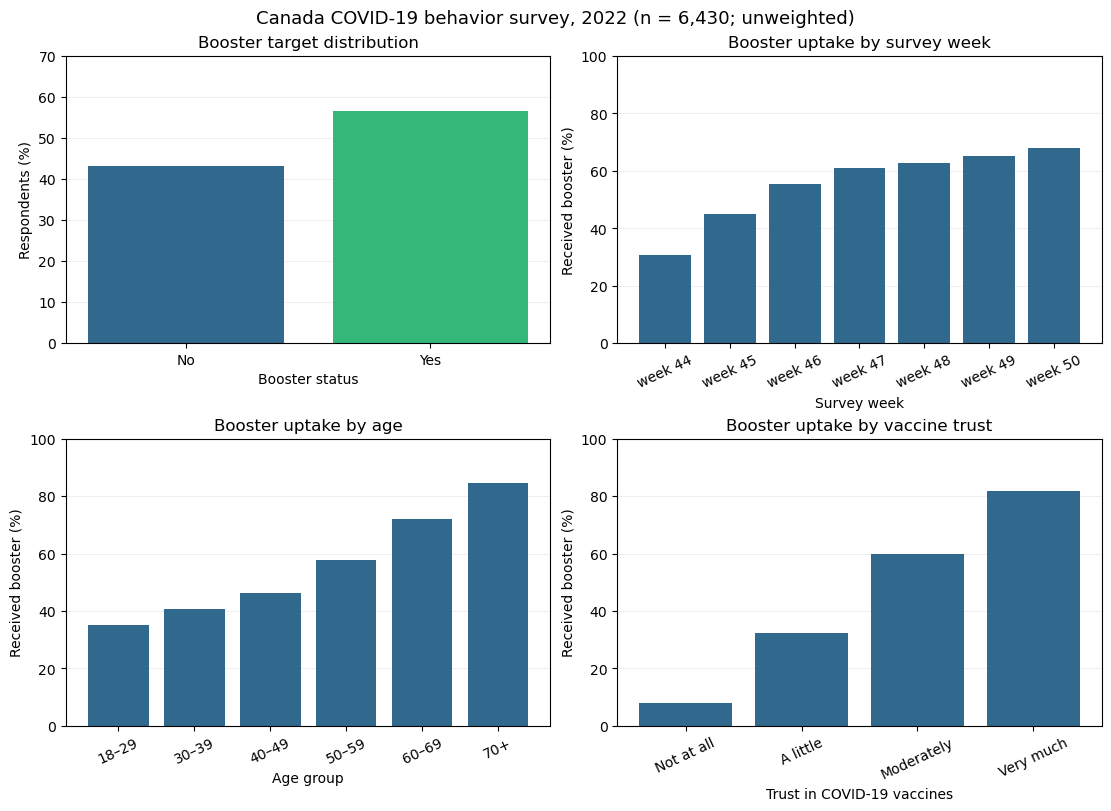

In [3]:
eda = cleaned_data.copy()
eda["booster_yes"] = eda["vac_boost_1"].eq("Yes")
eda["age_group"] = pd.cut(
    eda["age"],
    bins=[17, 29, 39, 49, 59, 69, 120],
    labels=["18–29", "30–39", "40–49", "50–59", "60–69", "70+"],
)

target_table = eda["vac_boost_1"].value_counts().rename_axis("booster").to_frame("n")
target_table["percent"] = target_table["n"] / len(eda) * 100
print("Target distribution:")
print(target_table.round(1).to_string())

def uptake_table(group, order=None):
    table = eda.groupby(group, observed=True)["booster_yes"].agg(n="size", booster_rate="mean")
    return table.reindex(order) if order is not None else table

week_order = [f"week {number}" for number in range(44, 51)]
trust_order = ["Not at all", "A little", "Moderately", "Very much"]
week_uptake = uptake_table("qweek", week_order)
age_uptake = uptake_table("age_group")
trust_uptake = uptake_table("vac7", trust_order)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
target_values = target_table.reindex(["No", "Yes"])
axes[0, 0].bar(target_values.index, target_values["percent"], color=["#31688e", "#35b779"])
axes[0, 0].set(title="Booster target distribution", xlabel="Booster status", ylabel="Respondents (%)", ylim=(0, 70))

for ax, table, xlabel, title in [
    (axes[0, 1], week_uptake, "Survey week", "Booster uptake by survey week"),
    (axes[1, 0], age_uptake, "Age group", "Booster uptake by age"),
    (axes[1, 1], trust_uptake, "Trust in COVID-19 vaccines", "Booster uptake by vaccine trust"),
]:
    values = table["booster_rate"] * 100
    ax.bar(table.index.astype(str), values, color="#31688e")
    ax.set(title=title, xlabel=xlabel, ylabel="Received booster (%)", ylim=(0, 100))
    ax.tick_params(axis="x", rotation=25)

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Canada COVID-19 behavior survey, 2022 (n = 6,430; unweighted)", fontsize=13)
plt.show()

The EDA is descriptive rather than causal. In particular, `qweek` may capture time-related rollout effects, so a random split may be more optimistic than a future-period validation.

## 3. Reconcile the 101 versus 85 missing-column counts

After restoring all 6,430 respondents, 101 columns contain missing values. Sixteen of them have no observations among respondents who directly answered the booster question; they are reasons asked only of people with neither first nor second dose. These columns are structurally tied to the target construction and are excluded. The remaining count is exactly 85.

In [4]:
columns_with_missing = [name for name in cleaned_data if cleaned_data[name].isna().any()]
direct_booster_answer = original_booster_response.notna()
never_vaccinated_branch = [
    name for name in columns_with_missing
    if cleaned_data.loc[direct_booster_answer, name].notna().sum() == 0
]
missing_85 = [name for name in columns_with_missing if name not in never_vaccinated_branch]

print(f"Columns with missing values: {len(columns_with_missing)}")
print(f"Excluded never-vaccinated branch: {len(never_vaccinated_branch)}")
print(f"Model 2 missing-column pool: {len(missing_85)}")
assert len(columns_with_missing) == 101
assert len(never_vaccinated_branch) == 16
assert len(missing_85) == 85
print("\nExcluded 16 columns:")
print(never_vaccinated_branch)

Columns with missing values: 101
Excluded never-vaccinated branch: 16
Model 2 missing-column pool: 85

Excluded 16 columns:
['vac_1', 'vac12_1', 'vac12_2', 'vac12_3', 'vac12_4', 'vac12_11', 'vac12_5', 'vac12_6', 'vac12_7', 'vac12_8', 'vac12_9', 'vac12_10', 'vac12_96', 'vac12_other', 'vac12_12', 'vac12_13']


           variable  missing_n  missing_pct  observed_levels
          Soc2_open       6297         97.9              103
            q_other       6191         96.3              206
vac12_booster_other       6046         94.0              370
   i14_health_other       5929         92.2              358
         long_covid       5635         87.6                5
              WAH_2       5493         85.4                5
              WAH_1       5493         85.4                5
              WAH_3       5493         85.4                5
             Soc2_1       5469         85.1                2
             Soc2_2       5469         85.1                2
             Soc2_3       5469         85.1                2
             Soc2_4       5469         85.1                2
             Soc2_5       5469         85.1                2
             Soc2_6       5469         85.1                2
          had_covid       5459         84.9                2
           future_3     

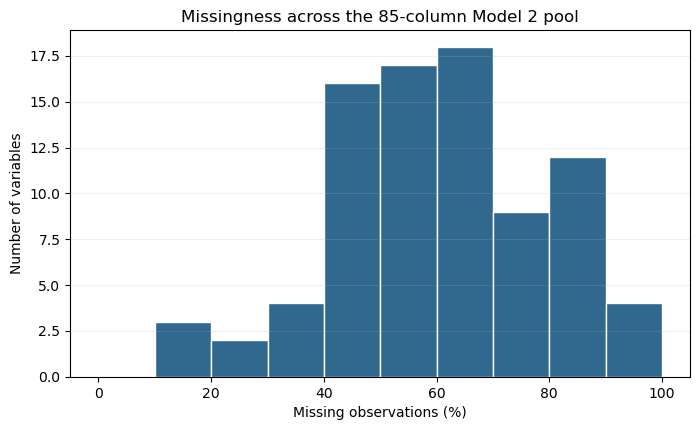

In [5]:
missing_summary = pd.DataFrame({
    "variable": missing_85,
    "missing_n": [cleaned_data[name].isna().sum() for name in missing_85],
    "missing_pct": [cleaned_data[name].isna().mean() * 100 for name in missing_85],
    "observed_levels": [cleaned_data[name].nunique(dropna=True) for name in missing_85],
}).sort_values("missing_pct", ascending=False)
print(missing_summary.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(missing_summary["missing_pct"], bins=np.arange(0, 105, 10), color="#31688e", edgecolor="white")
ax.set(title="Missingness across the 85-column Model 2 pool", xlabel="Missing observations (%)", ylabel="Number of variables")
ax.grid(axis="y", alpha=0.2)
plt.show()

## 4. Remove target leakage and free-text fields

Booster follow-up questions are asked conditionally based on booster status, so their presence or absence reveals the target. Free-text responses have very high cardinality and cannot be meaningfully represented as ordinary categories for k-NN. Both groups are documented and excluded before screening.

In [6]:
booster_followup_columns = [
    name for name in missing_85
    if ("boost" in name.lower() and name != "vac_boost_1")
]
free_text_columns = [
    name for name in ["i14_health_other", "Soc2_open", "q_other"]
    if name in missing_85
]
excluded_model2_columns = sorted(set(booster_followup_columns + free_text_columns))
eligible_missing_predictors = [
    name for name in missing_85 if name not in excluded_model2_columns
]

print(f"Booster follow-up leakage columns excluded: {len(booster_followup_columns)}")
print(booster_followup_columns)
print(f"\nFree-text columns excluded: {len(free_text_columns)}")
print(free_text_columns)
print(f"\nEligible missing-value predictors: {len(eligible_missing_predictors)}")

Booster follow-up leakage columns excluded: 14
['vac_boost_2', 'vac12_booster_1', 'vac12_booster_2', 'vac12_booster_3', 'vac12_booster_4', 'vac12_booster_5', 'vac12_booster_6', 'vac12_booster_7', 'vac12_booster_8', 'vac12_booster_9', 'vac12_booster_10', 'vac12_booster_96', 'vac12_booster_other', 'vac_boost_beyond']

Free-text columns excluded: 3
['i14_health_other', 'Soc2_open', 'q_other']

Eligible missing-value predictors: 68


## 5. Create the same seeded train/test split

Use `SEED = 20261110`, matching the final Model 1 development split. Model 2 screening and tuning use only the 70% training portion. The test portion remains unscored.

In [7]:
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 20261110
train_data, test_data = train_test_split(
    cleaned_data,
    test_size=0.30,
    random_state=SEED,
    stratify=cleaned_data["vac_boost_1"],
)
validation_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_train = train_data["vac_boost_1"].eq("Yes").astype(int)
print(f"Training set: {len(train_data):,} rows")
print(f"Reserved test set: {len(test_data):,} rows — not scored")

Training set: 4,501 rows
Reserved test set: 1,929 rows — not scored


## 6. Reproduce selection of the 14 complete-data predictors

Start from the 57 non-target columns in the 58-column complete table. Exclude `RecordNo`, `endtime`, survey `weight`, and `vac` (used to infer 644 skipped target values). On the training set only:

1. use L1 logistic regression with 5-fold CV to reduce 53 candidates; the exact nonzero count may vary slightly by solver version; the exact nonzero count may vary slightly by solver version; the exact nonzero count may vary slightly by solver version;
2. rank retained variables by drop-column change in validation AUC;
3. compare nested Top 5/8/10/12/15 sets with the submitted k-NN algorithm;
4. retain the best-AUC set. `WCRex1` is also audited separately because its wording is not clearly aligned with the Canadian business problem.

This is predictive screening, not a statistical-significance test.

In [8]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import cross_val_score

complete_table = cleaned_data.dropna(axis=1, how="any").copy()
assert complete_table.shape[1] == 58
excluded_complete_fields = {"vac_boost_1", "RecordNo", "endtime", "weight", "vac"}
complete_candidates = [
    name for name in complete_table.columns if name not in excluded_complete_fields
]
X_complete_train = train_data[complete_candidates]
complete_numeric = X_complete_train.select_dtypes(include="number").columns.tolist()
complete_categorical = [name for name in complete_candidates if name not in complete_numeric]

complete_preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), complete_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), complete_categorical),
])
complete_selector = Pipeline([
    ("preprocess", complete_preprocess),
    ("logistic", LogisticRegressionCV(
        Cs=[0.01, 0.03, 0.1, 0.3, 1.0],
        cv=validation_cv,
        penalty="l1",
        solver="liblinear",
        scoring="roc_auc",
        max_iter=2000,
        random_state=SEED,
        n_jobs=1,
        refit=True,
    )),
])
complete_selector.fit(X_complete_train, y_train)
complete_l1 = complete_selector.named_steps["logistic"]
encoded_complete_names = complete_selector.named_steps["preprocess"].get_feature_names_out()
complete_coefficients = complete_l1.coef_[0]
nonzero_complete_terms = np.abs(complete_coefficients) > 1e-8

l1_retained_variables = []
for variable in complete_candidates:
    prefix = f"categorical__{variable}_"
    match = (
        (encoded_complete_names == f"numeric__{variable}")
        | np.array([name.startswith(prefix) for name in encoded_complete_names])
    )
    if np.any(nonzero_complete_terms & match):
        l1_retained_variables.append(variable)

cv_auc_by_c = pd.DataFrame({
    "C": complete_l1.Cs_,
    "mean_CV_AUC": complete_l1.scores_[1].mean(axis=0),
    "SD_CV_AUC": complete_l1.scores_[1].std(axis=0),
})
print(f"Complete-data candidate predictors: {len(complete_candidates)}")
print(f"Selected L1 C: {complete_l1.C_[0]}")
print(f"Variables with at least one nonzero term: {len(l1_retained_variables)}")
print(cv_auc_by_c.round(4).to_string(index=False))
assert len(complete_candidates) == 53
# The exact nonzero count can vary slightly by sklearn/liblinear version.
assert len(l1_retained_variables) >= 30

Complete-data candidate predictors: 53
Selected L1 C: 0.1
Variables with at least one nonzero term: 33
   C  mean_CV_AUC  SD_CV_AUC
0.01       0.8214     0.0132
0.03       0.8570     0.0102
0.10       0.8707     0.0118
0.30       0.8693     0.0116
1.00       0.8644     0.0126


In [9]:
def logistic_screen_pipeline(features):
    numeric = [name for name in features if name in complete_numeric]
    categorical = [name for name in features if name not in numeric]
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])
    return Pipeline([
        ("preprocess", preprocessing),
        ("logistic", LogisticRegression(
            max_iter=2000, solver="liblinear", random_state=SEED
        )),
    ])

full_l1_scores = cross_val_score(
    logistic_screen_pipeline(l1_retained_variables),
    train_data[l1_retained_variables],
    y_train,
    cv=validation_cv,
    scoring="roc_auc",
    n_jobs=-1,
)
full_l1_auc = full_l1_scores.mean()
drop_rows = []
for variable in l1_retained_variables:
    reduced = [name for name in l1_retained_variables if name != variable]
    scores = cross_val_score(
        logistic_screen_pipeline(reduced),
        train_data[reduced],
        y_train,
        cv=validation_cv,
        scoring="roc_auc",
        n_jobs=-1,
    )
    drop_rows.append({
        "variable": variable,
        "mean_auc_without": scores.mean(),
        "auc_loss_when_removed": full_l1_auc - scores.mean(),
    })

complete_drop_ranking = pd.DataFrame(drop_rows).sort_values(
    "auc_loss_when_removed", ascending=False
).reset_index(drop=True)
ranked_complete_variables = complete_drop_ranking["variable"].tolist()
print(f"Full {len(l1_retained_variables)}-variable mean CV AUC: {full_l1_auc:.4f}")
print("Top 20 variables from the training-only drop-column ranking:")
print(complete_drop_ranking.head(20).round(4).to_string(index=False))

Full 33-variable mean CV AUC: 0.8692
Top 20 variables from the training-only drop-column ranking:
          variable  mean_auc_without  auc_loss_when_removed
             qweek            0.8459                 0.0233
              vac7            0.8614                 0.0078
               age            0.8614                 0.0078
         vac_man_7            0.8680                 0.0012
              r1_2            0.8682                 0.0011
    cantril_ladder            0.8684                 0.0008
      i12_health_8            0.8686                 0.0007
 employment_status            0.8686                 0.0006
            vac2_7            0.8686                 0.0006
      i12_health_7            0.8687                 0.0005
            vac2_1            0.8688                 0.0004
            WCRex1            0.8689                 0.0003
         vac_man_3            0.8690                 0.0002
            vac2_2            0.8690                 0.0002
  

In [10]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

complete_feature_sets = {
    "Top 5": ranked_complete_variables[:5],
    "Top 8": ranked_complete_variables[:8],
    "Top 10": ranked_complete_variables[:10],
    "Top 12": ranked_complete_variables[:12],
    "Top 15": ranked_complete_variables[:15],
    "Top 15 without WCRex1": [
        name for name in ranked_complete_variables[:15] if name != "WCRex1"
    ],
}
complete_knn_grid = {
    "classifier__n_neighbors": [5, 10, 15, 20, 30, 40, 60],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2],
}
screening_scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "recall_no": make_scorer(recall_score, pos_label=0),
}

complete_knn_searches = {}
feature_set_rows = []
for set_name, features in complete_feature_sets.items():
    numeric = [name for name in features if name in ["age", "cantril_ladder"]]
    categorical = [name for name in features if name not in numeric]
    feature_preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])
    feature_pipeline = Pipeline([
        ("preprocess", feature_preprocess),
        ("classifier", KNeighborsClassifier()),
    ])
    search = GridSearchCV(
        feature_pipeline,
        complete_knn_grid,
        scoring=screening_scoring,
        refit="roc_auc",
        cv=validation_cv,
        n_jobs=-1,
        return_train_score=False,
    )
    search.fit(train_data[features], y_train)
    complete_knn_searches[set_name] = search
    best = search.best_index_
    feature_set_rows.append({
        "feature_set": set_name,
        "n_variables": len(features),
        "best_k": search.best_params_["classifier__n_neighbors"],
        "weights": search.best_params_["classifier__weights"],
        "distance": "Manhattan" if search.best_params_["classifier__p"] == 1 else "Euclidean",
        "mean_CV_ROC_AUC": search.cv_results_["mean_test_roc_auc"][best],
        "mean_CV_accuracy": search.cv_results_["mean_test_accuracy"][best],
        "mean_CV_recall_No": search.cv_results_["mean_test_recall_no"][best],
    })

complete_feature_comparison = pd.DataFrame(feature_set_rows).sort_values(
    ["mean_CV_ROC_AUC", "mean_CV_recall_No"], ascending=False
)
selected_complete_set = complete_feature_comparison.iloc[0]["feature_set"]
model1_features = complete_feature_sets[selected_complete_set]
expected_model1_features = [
    "qweek", "vac7", "age", "vac_man_7", "r1_2", "cantril_ladder",
    "i12_health_8", "employment_status", "vac2_7", "i12_health_7",
    "vac2_1", "vac_man_3", "vac2_2", "r1_8",
]
print(complete_feature_comparison.round(4).to_string(index=False))
print(f"\nSelected complete-data feature set: {selected_complete_set}")
print(model1_features)


          feature_set  n_variables  best_k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
Top 15 without WCRex1           14      60 distance Manhattan           0.8558            0.7716             0.6403
               Top 15           15      30 distance Manhattan           0.8526            0.7740             0.6429
               Top 10           10      60 distance Manhattan           0.8505            0.7718             0.6773
                Top 5            5      60  uniform Euclidean           0.8493            0.7707             0.7080
                Top 8            8      30  uniform Manhattan           0.8483            0.7665             0.6855
               Top 12           12      40 distance Manhattan           0.8465            0.7581             0.6567

Selected complete-data feature set: Top 15 without WCRex1
['qweek', 'vac7', 'age', 'vac_man_7', 'r1_2', 'cantril_ladder', 'i12_health_8', 'employment_status', 'vac2_7', 'i12_health_7', 'v

The 14-variable set is therefore reproduced from the current training split rather than typed into the Model 2 definition. Removing `WCRex1` improves mean validation AUC, and the selected variables are passed forward without using test performance.

### Descriptive relationships for the two retained missing-value predictors

Show booster uptake in the training data, including the explicit missing category. This makes clear that missingness itself can carry questionnaire-routing information.

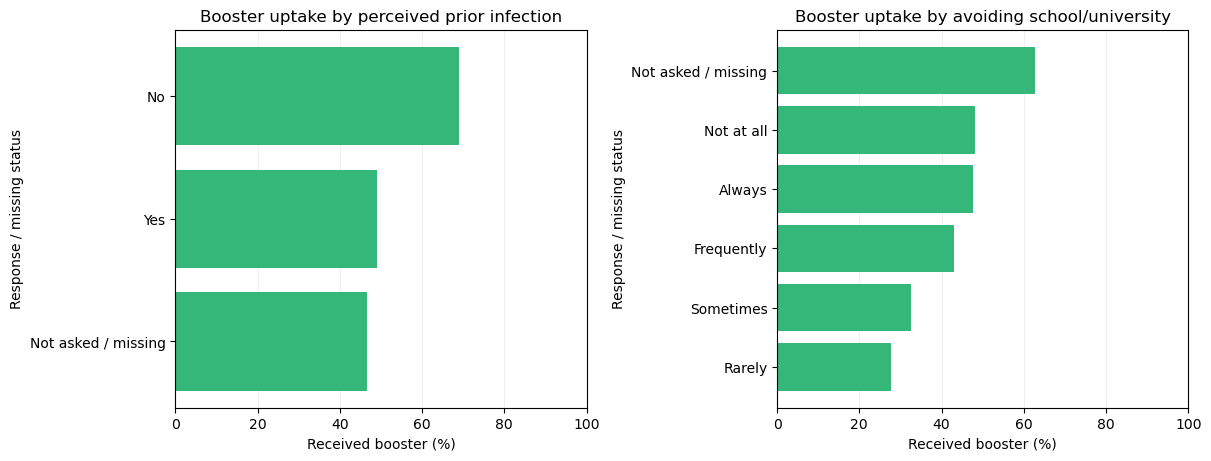

In [11]:
missing_eda = train_data[["vac_boost_1", "had_covid_2", "i12_health_10"]].copy()
missing_eda["booster_yes"] = missing_eda["vac_boost_1"].eq("Yes")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, variable, title in [
    (axes[0], "had_covid_2", "Booster uptake by perceived prior infection"),
    (axes[1], "i12_health_10", "Booster uptake by avoiding school/university"),
]:
    display_values = missing_eda[variable].fillna("Not asked / missing")
    table = missing_eda.assign(group=display_values).groupby("group", observed=True)["booster_yes"].agg(n="size", rate="mean")
    table = table.sort_values("rate")
    ax.barh(table.index.astype(str), table["rate"] * 100, color="#35b779")
    ax.set(title=title, xlabel="Received booster (%)", ylabel="Response / missing status", xlim=(0, 100))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()

## 7. Training-only screening of missing-value predictors

Process every eligible missing-value predictor inside the modeling pipeline. Treat `i2_health` as numeric: median-impute it, add a missingness indicator, and standardize it. Treat all other fields as categorical: replace missing values with the explicit category `Not asked / missing`, then one-hot encode. L1 logistic regression is used only to screen variables on training folds; it is not Model 2's final algorithm.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

screening_data = train_data[eligible_missing_predictors].copy()
screening_data["i2_health"] = pd.to_numeric(screening_data["i2_health"], errors="coerce")
numeric_missing = ["i2_health"]
categorical_missing = [name for name in eligible_missing_predictors if name not in numeric_missing]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Not asked / missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
screening_preprocess = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_missing),
    ("categorical", categorical_pipeline, categorical_missing),
])
missing_selector = Pipeline([
    ("preprocess", screening_preprocess),
    ("logistic", LogisticRegressionCV(
        Cs=[0.01, 0.03, 0.1, 0.3, 1.0],
        cv=validation_cv,
        penalty="l1",
        solver="liblinear",
        scoring="roc_auc",
        max_iter=3000,
        random_state=SEED,
        n_jobs=1,
        refit=True,
    )),
])
missing_selector.fit(screening_data, y_train)
selector_model = missing_selector.named_steps["logistic"]
print(f"Screened missing-value predictors: {len(eligible_missing_predictors)}")
print(f"Selected C: {selector_model.C_[0]}")
print(f"Best mean training-fold AUC: {selector_model.scores_[1].mean(axis=0).max():.4f}")

Screened missing-value predictors: 68
Selected C: 0.3
Best mean training-fold AUC: 0.7408


In [13]:
encoded_names = missing_selector.named_steps["preprocess"].get_feature_names_out()
coefficients = selector_model.coef_[0]
importance_rows = []
for variable in eligible_missing_predictors:
    if variable == "i2_health":
        match = np.array([
            ("i2_health" in name) for name in encoded_names
        ])
    else:
        match = np.array([
            name.startswith(f"categorical__{variable}_") for name in encoded_names
        ])
    variable_coefficients = np.abs(coefficients[match])
    importance_rows.append({
        "variable": variable,
        "max_abs_coefficient": variable_coefficients.max() if len(variable_coefficients) else 0.0,
        "nonzero_terms": int((variable_coefficients > 1e-8).sum()),
        "missing_pct": cleaned_data[variable].isna().mean() * 100,
    })
missing_importance = pd.DataFrame(importance_rows).sort_values(
    ["max_abs_coefficient", "nonzero_terms"], ascending=False
)
retained_missing = missing_importance.query("nonzero_terms > 0").copy()
print(f"Missing-value variables with at least one nonzero term: {len(retained_missing)}")
print(retained_missing.head(25).round(4).to_string(index=False))

Missing-value variables with at least one nonzero term: 53
     variable  max_abs_coefficient  nonzero_terms  missing_pct
    travel1_4               0.8747              1      74.6345
  d1_health_8               0.6693              2      47.0918
i12_health_10               0.6391              5      68.3981
     future_1               0.5680              3      25.3655
i12_health_23               0.5488              3      15.5677
    had_covid               0.5413              2      84.8989
  had_covid_2               0.5413              1      44.4790
 i12_health_9               0.5244              3      55.9876
           w2               0.5168              3      74.6345
i12_health_11               0.5065              5      15.5677
 i14_health_7               0.5059              2      55.9876
 i12_health_2               0.4467              4      15.5677
i12_health_24               0.4203              4      55.9876
  d1_health_5               0.4170              2      47.0

## 8. Build and cross-validate Model 2

Add the 15 highest-ranked missing-value predictors to Model 1's locked 14 predictors. This gives Model 2 a controlled opportunity to benefit from missing-value information without allowing all conditional survey branches to dominate k-NN distance. Tune Model 2 only on training folds and compare it with the locked Model 1 training-CV result.

In [14]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier

model1_features = [
    "qweek", "vac7", "age", "vac_man_7", "r1_2", "cantril_ladder",
    "i12_health_8", "employment_status", "vac2_7", "i12_health_7",
    "vac2_1", "vac_man_3", "vac2_2", "r1_8",
]
added_missing_features = retained_missing.head(15)["variable"].tolist()
model2_features = model1_features + [
    name for name in added_missing_features if name not in model1_features
]
print(f"Model 1 variables: {len(model1_features)}")
print(f"Added missing-value variables: {len(added_missing_features)}")
print(added_missing_features)
print(f"Model 2 total variables: {len(model2_features)}")

Model 1 variables: 14
Added missing-value variables: 15
['travel1_4', 'd1_health_8', 'i12_health_10', 'future_1', 'i12_health_23', 'had_covid', 'had_covid_2', 'i12_health_9', 'w2', 'i12_health_11', 'i14_health_7', 'i12_health_2', 'i12_health_24', 'd1_health_5', 'travel1_2']
Model 2 total variables: 29


In [15]:
def make_knn_pipeline(features):
    numeric = [name for name in features if name in ["age", "cantril_ladder", "i2_health"]]
    categorical = [name for name in features if name not in numeric]
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Not asked / missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ("numeric", numeric_steps, numeric),
        ("categorical", categorical_steps, categorical),
    ])
    return Pipeline([
        ("preprocess", prep),
        ("classifier", KNeighborsClassifier()),
    ])

X_model2_train = train_data[model2_features].copy()
if "i2_health" in X_model2_train:
    X_model2_train["i2_health"] = pd.to_numeric(X_model2_train["i2_health"], errors="coerce")

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "recall_no": make_scorer(recall_score, pos_label=0),
}
model2_grid = {
    "classifier__n_neighbors": [20, 40, 60, 80, 100],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2],
}
model2_search = GridSearchCV(
    make_knn_pipeline(model2_features),
    model2_grid,
    scoring=scoring,
    refit="roc_auc",
    cv=validation_cv,
    n_jobs=-1,
    return_train_score=False,
)
model2_search.fit(X_model2_train, y_train)
best_index = model2_search.best_index_
model2_summary = {
    "model": "Model 2",
    "variables": len(model2_features),
    "k": model2_search.best_params_["classifier__n_neighbors"],
    "weights": model2_search.best_params_["classifier__weights"],
    "distance": "Manhattan" if model2_search.best_params_["classifier__p"] == 1 else "Euclidean",
    "mean_CV_ROC_AUC": model2_search.cv_results_["mean_test_roc_auc"][best_index],
    "mean_CV_accuracy": model2_search.cv_results_["mean_test_accuracy"][best_index],
    "mean_CV_recall_No": model2_search.cv_results_["mean_test_recall_no"][best_index],
}
print(pd.DataFrame([model2_summary]).round(4).to_string(index=False))

  model  variables  k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
Model 2         29 60 distance Euclidean           0.8619            0.7692             0.6136


                 model  variables  k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
Complete-data baseline         14 60 distance Manhattan           0.8558            0.7716             0.6403
               Model 2         29 60 distance Euclidean           0.8619            0.7692             0.6136


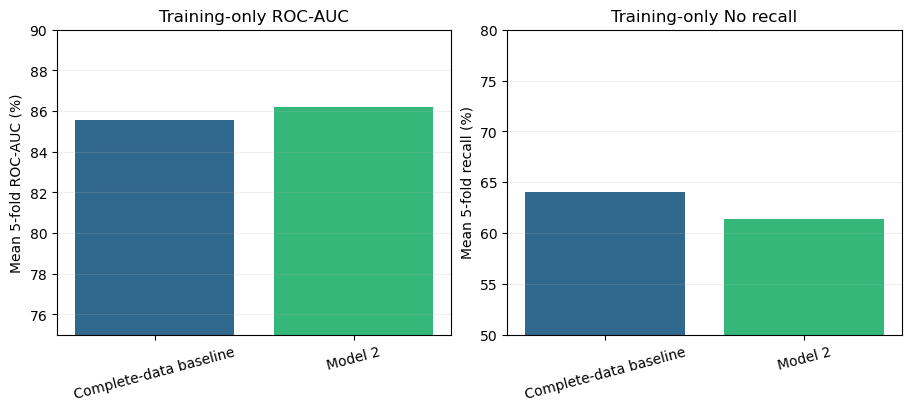

In [16]:
model1_search = complete_knn_searches["Top 15 without WCRex1"]
model1_best_index = model1_search.best_index_
model1_summary = {
    "model": "Complete-data baseline",
    "variables": len(model1_features),
    "k": model1_search.best_params_["classifier__n_neighbors"],
    "weights": model1_search.best_params_["classifier__weights"],
    "distance": "Manhattan" if model1_search.best_params_["classifier__p"] == 1 else "Euclidean",
    "mean_CV_ROC_AUC": model1_search.cv_results_["mean_test_roc_auc"][model1_best_index],
    "mean_CV_accuracy": model1_search.cv_results_["mean_test_accuracy"][model1_best_index],
    "mean_CV_recall_No": model1_search.cv_results_["mean_test_recall_no"][model1_best_index],
}
comparison = pd.DataFrame([model1_summary, model2_summary])
print(comparison.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].bar(comparison["model"], comparison["mean_CV_ROC_AUC"] * 100, color=["#31688e", "#35b779"])
axes[0].set(title="Training-only ROC-AUC", ylabel="Mean 5-fold ROC-AUC (%)", ylim=(75, 90))
axes[1].bar(comparison["model"], comparison["mean_CV_recall_No"] * 100, color=["#31688e", "#35b779"])
axes[1].set(title="Training-only No recall", ylabel="Mean 5-fold recall (%)", ylim=(50, 80))
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.2)
plt.show()

## Takeaway

Model 2 is a training-only experiment. Missingness is treated as information only after removing target-derived branches and free text. Do not evaluate Model 2 on the reserved test set unless its predictor set and hyperparameters are explicitly locked first.

## 9. Audit the 15 added variables

Hold Model 2's current k-NN parameters fixed (`k=60`, distance weighting, Euclidean distance). Remove each added variable one at a time and rerun the same five training folds. Define incremental contribution as:

`full Model 2 mean CV AUC − mean CV AUC without the variable`

A positive value means the variable adds predictive information conditional on the other 28 variables. This is a predictive ablation measure, not a p-value.

In [17]:
from sklearn.model_selection import cross_val_score

fixed_model2_pipeline = make_knn_pipeline(model2_features)
fixed_model2_pipeline.set_params(
    classifier__n_neighbors=60,
    classifier__weights="distance",
    classifier__p=2,
)
full_model2_scores = cross_val_score(
    fixed_model2_pipeline,
    X_model2_train,
    y_train,
    cv=validation_cv,
    scoring="roc_auc",
    n_jobs=-1,
)
full_model2_auc = full_model2_scores.mean()

ablation_rows = []
for variable in added_missing_features:
    reduced_features = [name for name in model2_features if name != variable]
    reduced_data = train_data[reduced_features].copy()
    if "i2_health" in reduced_data:
        reduced_data["i2_health"] = pd.to_numeric(reduced_data["i2_health"], errors="coerce")
    reduced_pipeline = make_knn_pipeline(reduced_features)
    reduced_pipeline.set_params(
        classifier__n_neighbors=60,
        classifier__weights="distance",
        classifier__p=2,
    )
    reduced_scores = cross_val_score(
        reduced_pipeline,
        reduced_data,
        y_train,
        cv=validation_cv,
        scoring="roc_auc",
        n_jobs=-1,
    )
    ablation_rows.append({
        "variable": variable,
        "missing_pct": cleaned_data[variable].isna().mean() * 100,
        "mean_auc_without": reduced_scores.mean(),
        "auc_loss_when_removed": full_model2_auc - reduced_scores.mean(),
    })

ablation_table = pd.DataFrame(ablation_rows).sort_values(
    "auc_loss_when_removed", ascending=False
)
print(f"Full 29-variable Model 2 mean CV AUC: {full_model2_auc:.4f}")
print(ablation_table.round(4).to_string(index=False))

Full 29-variable Model 2 mean CV AUC: 0.8619
     variable  missing_pct  mean_auc_without  auc_loss_when_removed
  had_covid_2      44.4790            0.8603                 0.0016
i12_health_10      68.3981            0.8604                 0.0015
    travel1_4      74.6345            0.8616                 0.0003
     future_1      25.3655            0.8618                 0.0002
 i12_health_9      55.9876            0.8621                -0.0002
  d1_health_5      47.0918            0.8622                -0.0003
i12_health_23      15.5677            0.8623                -0.0004
    had_covid      84.8989            0.8623                -0.0004
           w2      74.6345            0.8624                -0.0005
  d1_health_8      47.0918            0.8624                -0.0005
i12_health_24      55.9876            0.8625                -0.0006
    travel1_2      74.6345            0.8626                -0.0007
i12_health_11      15.5677            0.8631                -0.0012
 i1

## 10. Build the reduced Model 2

Use a small practical cutoff: retain an added variable when removing it lowers mean CV AUC by at least 0.0005. For overlapping pairs (`had_covid` versus `had_covid_2`, and `travel1_4` versus `travel1_2`), retain at most the stronger member according to the same ablation result. This avoids counting nearly the same construct twice in k-NN distance.

In [18]:
keep_threshold = 0.0005
kept_added = ablation_table.loc[
    ablation_table["auc_loss_when_removed"] >= keep_threshold, "variable"
].tolist()

for overlapping_pair in [
    ["had_covid", "had_covid_2"],
    ["travel1_4", "travel1_2"],
]:
    present = [name for name in overlapping_pair if name in kept_added]
    if len(present) > 1:
        stronger = (
            ablation_table[ablation_table["variable"].isin(present)]
            .sort_values("auc_loss_when_removed", ascending=False)
            .iloc[0]["variable"]
        )
        kept_added = [name for name in kept_added if name not in present or name == stronger]

reduced_model2_features = model1_features + [
    name for name in kept_added if name not in model1_features
]
print(f"Added variables retained: {len(kept_added)}")
print(kept_added)
print(f"Reduced Model 2 variables: {len(reduced_model2_features)}")

Added variables retained: 2
['had_covid_2', 'i12_health_10']
Reduced Model 2 variables: 16


In [19]:
X_reduced_model2_train = train_data[reduced_model2_features].copy()
if "i2_health" in X_reduced_model2_train:
    X_reduced_model2_train["i2_health"] = pd.to_numeric(
        X_reduced_model2_train["i2_health"], errors="coerce"
    )

reduced_model2_search = GridSearchCV(
    make_knn_pipeline(reduced_model2_features),
    model2_grid,
    scoring=scoring,
    refit="roc_auc",
    cv=validation_cv,
    n_jobs=-1,
    return_train_score=False,
)
reduced_model2_search.fit(X_reduced_model2_train, y_train)
reduced_best_index = reduced_model2_search.best_index_
reduced_model2_summary = {
    "model": "Reduced Model 2",
    "variables": len(reduced_model2_features),
    "k": reduced_model2_search.best_params_["classifier__n_neighbors"],
    "weights": reduced_model2_search.best_params_["classifier__weights"],
    "distance": "Manhattan" if reduced_model2_search.best_params_["classifier__p"] == 1 else "Euclidean",
    "mean_CV_ROC_AUC": reduced_model2_search.cv_results_["mean_test_roc_auc"][reduced_best_index],
    "mean_CV_accuracy": reduced_model2_search.cv_results_["mean_test_accuracy"][reduced_best_index],
    "mean_CV_recall_No": reduced_model2_search.cv_results_["mean_test_recall_no"][reduced_best_index],
}
final_training_comparison = pd.DataFrame([
    comparison.iloc[0].to_dict(),
    model2_summary,
    reduced_model2_summary,
])
print(final_training_comparison.round(4).to_string(index=False))

                 model  variables  k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
Complete-data baseline         14 60 distance Manhattan           0.8558            0.7716             0.6403
               Model 2         29 60 distance Euclidean           0.8619            0.7692             0.6136
       Reduced Model 2         16 80 distance Manhattan           0.8631            0.7736             0.6306


## 11. Report all final Model 2 candidate settings

The table reports the leading combinations of k, voting weights, and distance metric from the same training-only 5-fold search. The curve shows the bias-variance tradeoff across k: very local neighborhoods can be unstable, while overly large neighborhoods smooth away useful local structure.

Top 10 final Model 2 candidate settings (training-only 5-fold CV):
  k  weights  distance  mean_CV_ROC_AUC  SD_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
 80 distance Manhattan           0.8631         0.0086            0.7736             0.6306
100 distance Manhattan           0.8627         0.0082            0.7703             0.6213
 60 distance Manhattan           0.8626         0.0084            0.7760             0.6413
100 distance Euclidean           0.8625         0.0077            0.7734             0.6475
 60 distance Euclidean           0.8623         0.0081            0.7792             0.6619
 80 distance Euclidean           0.8621         0.0076            0.7767             0.6547
100  uniform Euclidean           0.8618         0.0076            0.7723             0.6511
 80  uniform Manhattan           0.8615         0.0087            0.7736             0.6347
 60  uniform Euclidean           0.8614         0.0081            0.7798             0.6685
100  uniform 

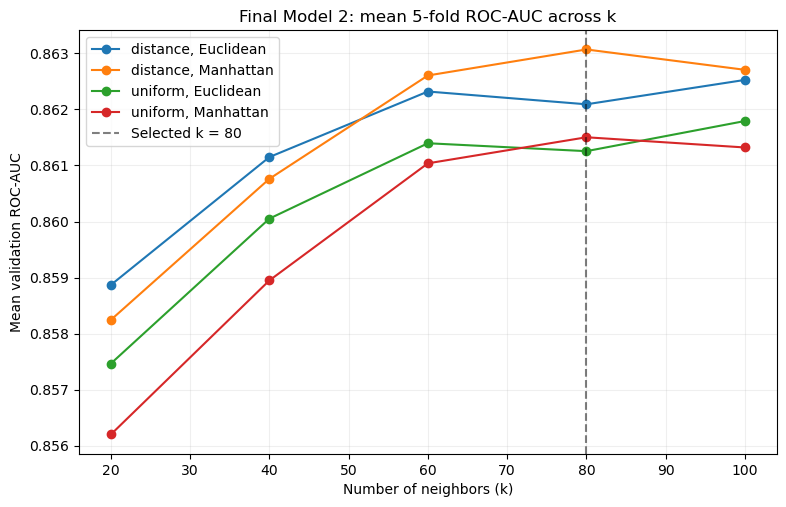

In [20]:
final_grid_results = pd.DataFrame(reduced_model2_search.cv_results_)
final_candidate_table = pd.DataFrame({
    "k": final_grid_results["param_classifier__n_neighbors"].astype(int),
    "weights": final_grid_results["param_classifier__weights"].astype(str),
    "distance": np.where(
        final_grid_results["param_classifier__p"].astype(int).eq(1),
        "Manhattan",
        "Euclidean",
    ),
    "mean_CV_ROC_AUC": final_grid_results["mean_test_roc_auc"],
    "SD_CV_ROC_AUC": final_grid_results["std_test_roc_auc"],
    "mean_CV_accuracy": final_grid_results["mean_test_accuracy"],
    "mean_CV_recall_No": final_grid_results["mean_test_recall_no"],
}).sort_values(["mean_CV_ROC_AUC", "mean_CV_recall_No"], ascending=False)

print("Top 10 final Model 2 candidate settings (training-only 5-fold CV):")
print(final_candidate_table.head(10).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
for (weights, distance), subset in final_candidate_table.groupby(["weights", "distance"]):
    subset = subset.sort_values("k")
    ax.plot(
        subset["k"], subset["mean_CV_ROC_AUC"], marker="o",
        label=f"{weights}, {distance}",
    )
ax.axvline(80, color="black", linestyle="--", alpha=0.5, label="Selected k = 80")
ax.set(
    title="Final Model 2: mean 5-fold ROC-AUC across k",
    xlabel="Number of neighbors (k)",
    ylabel="Mean validation ROC-AUC",
)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

The selected setting is `k=80`, distance weighting, and Manhattan distance. It maximizes mean validation ROC-AUC in the prespecified final grid; nearby k values are similar, so the result should be interpreted as a broad stable region rather than a uniquely exact k.

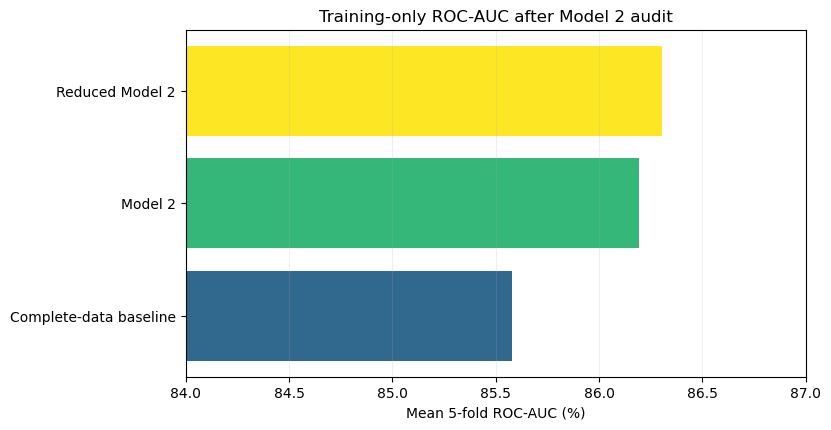

In [21]:
plot_data = final_training_comparison.sort_values("mean_CV_ROC_AUC")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_data["model"], plot_data["mean_CV_ROC_AUC"] * 100, color=["#31688e", "#35b779", "#fde725"])
ax.set(title="Training-only ROC-AUC after Model 2 audit", xlabel="Mean 5-fold ROC-AUC (%)", xlim=(84, 87))
ax.grid(axis="x", alpha=0.2)
plt.show()

## Model 2 audit status

Choose between the original and reduced Model 2 using training-fold ROC-AUC, complexity, and semantic defensibility. The reserved test set remains unscored. Lock the final Model 2 specification before any test evaluation.

## 12. Final locked Model 2 test evaluation

Lock the reduced Model 2 before viewing test performance:

- 16 predictors: Model 1's 14 plus `had_covid_2` and `i12_health_10`
- `n_neighbors = 80`
- distance-weighted voting
- Manhattan distance (`p = 1`)
- primary model-selection metric: training-only 5-fold ROC-AUC

Fit on all 4,501 training rows and evaluate once on the 1,929 reserved test rows. Do not revise variables, preprocessing, threshold, or hyperparameters based on the test results.

In [22]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

assert reduced_model2_search.best_params_ == {
    "classifier__n_neighbors": 80,
    "classifier__p": 1,
    "classifier__weights": "distance",
}
locked_model2 = reduced_model2_search.best_estimator_
X_model2_test = test_data[reduced_model2_features].copy()
if "i2_health" in X_model2_test:
    X_model2_test["i2_health"] = pd.to_numeric(X_model2_test["i2_health"], errors="coerce")
y_model2_test = test_data["vac_boost_1"].eq("Yes").astype(int)
model2_test_probability = locked_model2.predict_proba(X_model2_test)[:, 1]
model2_test_prediction = locked_model2.predict(X_model2_test)

model2_test_accuracy = accuracy_score(y_model2_test, model2_test_prediction)
model2_test_auc = roc_auc_score(y_model2_test, model2_test_probability)
model2_test_confusion = confusion_matrix(
    y_model2_test, model2_test_prediction, labels=[0, 1]
)
model2_test_report = classification_report(
    y_model2_test,
    model2_test_prediction,
    labels=[0, 1],
    target_names=["No", "Yes"],
    digits=4,
    output_dict=True,
)
print(f"Locked Model 2 predictors: {len(reduced_model2_features)}")
print(f"Final test accuracy: {model2_test_accuracy:.4f}")
print(f"Final test ROC-AUC: {model2_test_auc:.4f}")
print("\nConfusion matrix (rows = actual No/Yes; columns = predicted No/Yes):")
print(model2_test_confusion)
print("\nClassification report:")
print(pd.DataFrame(model2_test_report).T.round(4).to_string())

Locked Model 2 predictors: 16
Final test accuracy: 0.7626
Final test ROC-AUC: 0.8549

Confusion matrix (rows = actual No/Yes; columns = predicted No/Yes):
[[520 315]
 [143 951]]

Classification report:
              precision  recall  f1-score    support
No               0.7843  0.6228    0.6943   835.0000
Yes              0.7512  0.8693    0.8059  1094.0000
accuracy         0.7626  0.7626    0.7626     0.7626
macro avg        0.7677  0.7460    0.7501  1929.0000
weighted avg     0.7655  0.7626    0.7576  1929.0000


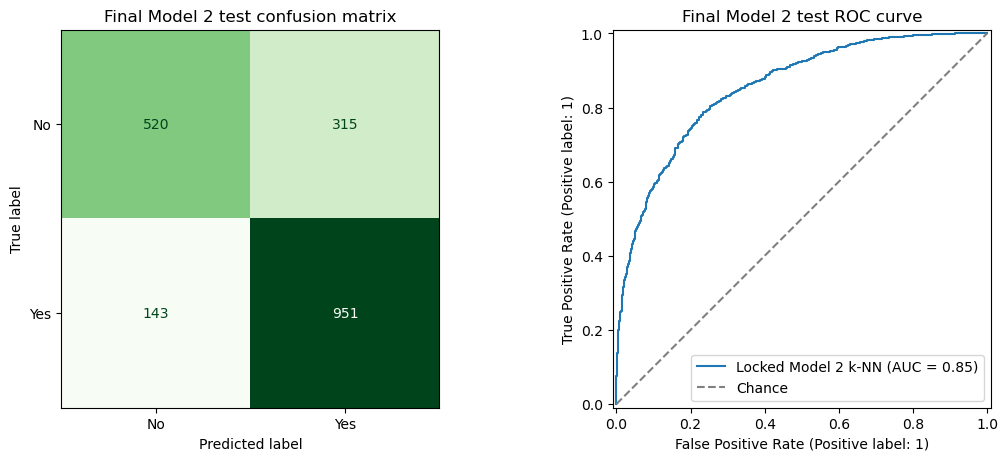

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ConfusionMatrixDisplay(
    confusion_matrix=model2_test_confusion,
    display_labels=["No", "Yes"],
).plot(ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("Final Model 2 test confusion matrix")
RocCurveDisplay.from_predictions(
    y_model2_test,
    model2_test_probability,
    name="Locked Model 2 k-NN",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].set_title("Final Model 2 test ROC curve")
axes[1].legend(loc="lower right")
plt.show()

In [24]:
final_model2_summary = pd.DataFrame([{
    "model": "Final Model 2",
    "variables": len(reduced_model2_features),
    "test_ROC_AUC": model2_test_auc,
    "test_accuracy": model2_test_accuracy,
    "test_precision_No": model2_test_report["No"]["precision"],
    "test_recall_No": model2_test_report["No"]["recall"],
    "test_F1_No": model2_test_report["No"]["f1-score"],
    "test_precision_Yes": model2_test_report["Yes"]["precision"],
    "test_recall_Yes": model2_test_report["Yes"]["recall"],
    "test_F1_Yes": model2_test_report["Yes"]["f1-score"],
}])
print(final_model2_summary.round(4).to_string(index=False))

        model  variables  test_ROC_AUC  test_accuracy  test_precision_No  test_recall_No  test_F1_No  test_precision_Yes  test_recall_Yes  test_F1_Yes
Final Model 2         16        0.8549         0.7626             0.7843          0.6228      0.6943              0.7512           0.8693       0.8059


## Final evaluation rule

These are the final reserved-test results for the already locked Model 2. Do not return to variable screening, missing-value strategy selection, or hyperparameter tuning based on these results.